# Validação da base limpa — Novo CAGED (setembro/2026)

Compara **raw × clean** e mede o efeito da limpeza no salário. Gerado por `scripts/limpeza.py` (regras R1–R6 documentadas no próprio script).
Somente leitura: `dados/original/` e `dados/tratados/` não são alterados aqui.

In [1]:
from pathlib import Path
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

AZUL, CINZA, LARANJA = "#2B6CB0", "#A0AEC0", "#DD6B20"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#E2E8F0", "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
MES = "202609"
meta = json.loads((RAIZ / "dados/tratados" / f"limpeza_meta_{MES}.json").read_text(encoding="utf-8"))
log = pd.read_csv(RAIZ / "dados/tratados" / f"limpeza_log_{MES}.csv")
clean = pd.read_parquet(RAIZ / "dados/tratados" / f"CAGEDMOV{MES}_clean.parquet")
raw = pd.read_csv(RAIZ / "dados/original" / f"CAGEDMOV{MES}.txt", sep=";", decimal=",",
                  usecols=["sexo", "saldomovimentação", "idade", "salário", "horascontratuais"])
print(f"raw: {len(raw):,} linhas | clean: {len(clean):,} linhas ({len(clean)/len(raw):.2%}) | piso detectado: R$ {meta['piso_detectado']:,.0f}")

raw: 4,307,569 linhas | clean: 4,250,945 linhas (98.69%) | piso detectado: R$ 1,621


## 1. Log de limpeza (o que cada regra fez)

In [2]:
log

,regra,acao,linhas_afetadas,pct_do_raw,linhas_restantes
0,Base original (raw),-,0,0.0000,4307569
1,R1 unidade de pagamento Tarefa/Variável/Não identificado,excluídas,47674,1.1067,4259895
2,R2 horas contratuais = 0,excluídas,0,0.0000,4259895
3,R3 idade ausente: imputada pela mediana da mesma categoria de trabalhador,"imputadas (cat 101: 31, cat 102: 35, cat 103: 18, cat 105: 33, cat 106: 29, cat 111: 31)",5285,0.1227,4259895
4,R4 salário ou valor fixo <= 0,excluídas,8808,0.2045,4251087
5,Conferência: salario_mensal calculado x `salário` do Ministério,100.0000% das linhas concordam,0,0.0000,4251087
6,R5 Hora com valor/hora >= 20% do salário mensal típico (digitado como mensal),corrigidas (salario_mensal = valor digitado),1806,0.0419,4251087
7,R5b Hora com valor/hora > 2x o salário mensal típico (não se encaixa nem como mensal),excluídas,31,0.0007,4251056
8,R6 salário mensal > 100x a mediana da ocupação,excluídas,111,0.0026,4250945
9,Info: linhas sem ocupação de referência (R5/R6 não se aplicam),mantidas,7,0.0002,4250945


## 2. Parâmetros: raw × clean
A limpeza não deveria mudar o perfil geral da base (sexo, admissões, idade); o que muda é a **escala do salário**.

In [3]:
def resumo(s_sexo, s_adm, s_idade, s_sal):
    return {"% mulheres": (s_sexo == 3).mean() * 100, "% admissões": (s_adm == 1).mean() * 100,
            "idade média": s_idade.mean(), "salário médio (R$)": s_sal.mean(), "salário mediano (R$)": s_sal.median(),
            "desvio-padrão do salário (R$)": s_sal.std(), "CV do salário": s_sal.std() / s_sal.mean(),
            "assimetria do salário": stats.skew(s_sal), "salário máximo (R$)": s_sal.max()}
r = resumo(raw["sexo"], raw["saldomovimentação"], raw["idade"].dropna(), raw["salário"])
c = resumo(clean["sexo"], clean["saldomovimentação"], clean["idade"], clean["salario_mensal"])
comp = pd.DataFrame({"raw (salário informado, sem filtro)": r, "clean (salario_mensal)": c})
comp["diferença"] = comp["clean (salario_mensal)"] - comp["raw (salário informado, sem filtro)"]
comp

,"raw (salário informado, sem filtro)",clean (salario_mensal),diferença
% mulheres,42.7667,42.8124,0.0457
% admissões,51.4080,51.4616,0.0536
idade média,33.0834,33.0667,-0.0167
salário médio (R$),"2,608.1454","2,459.3577",-148.7877
salário mediano (R$),"2,030.0000","2,034.6000",4.6000
desvio-padrão do salário (R$),"16,818.3164","2,409.6407","-14,408.6757"
CV do salário,6.4484,0.9798,-5.4686
assimetria do salário,"1,071.7142",32.8811,"-1,038.8331"
salário máximo (R$),"27,841,398.0000","759,256.0000","-27,082,142.0000"


## 3. Distribuição do salário antes e depois

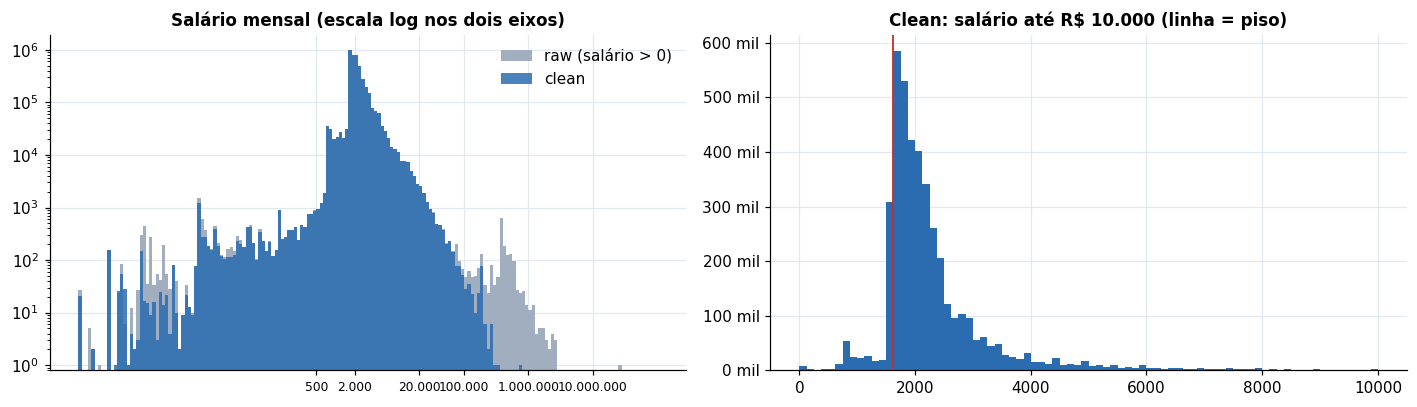

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
bins = np.arange(-1, 8.01, 0.05)
raw_pos = raw.loc[raw["salário"] > 0, "salário"]
ax[0].hist(np.log10(raw_pos), bins=bins, color=CINZA, label="raw (salário > 0)")
ax[0].hist(clean["log10_salario"], bins=bins, color=AZUL, alpha=.85, label="clean")
ax[0].set_yscale("log"); ax[0].set_ylim(0.8, None); ax[0].legend(frameon=False)
marcas = [500, 2000, 20000, 1e5, 1e6, 1e7]
ax[0].set_xticks(np.log10(marcas), [f"{m:,.0f}".replace(",", ".") for m in marcas], fontsize=8)
ax[0].set_title("Salário mensal (escala log nos dois eixos)")
ax[1].hist(clean.loc[clean["salario_mensal"] <= 10000, "salario_mensal"], bins=80, color=AZUL)
ax[1].axvline(meta["piso_detectado"], color="#C53030", lw=1.2); ax[1].set_title("Clean: salário até R$ 10.000 (linha = piso)")
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v/1e3:.0f} mil")
plt.tight_layout(); plt.show()

## 4. Os salários altos legítimos permanecem?
Nenhum teto fixo foi aplicado: só saem valores incompatíveis com a ocupação (R6) ou o erro "mensal digitado como hora" (R5/R5b).

In [5]:
s = clean["salario_mensal"]
print({f"> R$ {x:,.0f}".replace(",", "."): int((s > x).sum()) for x in [20000, 50000, 100000, 300000, 1e6]})
print("Maior salário do clean: R$ {:,.0f}".format(s.max()))
clean.nlargest(12, "salario_mensal")[["salario_mensal", "unidade_pagamento", "horascontratuais", "ocupacao", "salario_corrigido"]]

{'> R$ 20.000': 9083, '> R$ 50.000': 1003, '> R$ 100.000': 214, '> R$ 300.000': 2, '> R$ 1.000.000': 0}
Maior salário do clean: R$ 759,256


,salario_mensal,unidade_pagamento,horascontratuais,ocupacao,salario_corrigido
643154,"759,256.0000",Mês,20.0000,Médico Clínico,0
2433539,"345,600.0000",Mês,44.0000,Treinador Profissional de Futebol,0
2859037,"289,120.7800",Mês,40.0000,Diretor Comercial,0
114107,"274,726.0000",Mês,30.0000,Farmaceutico,0
1270199,"270,833.0000",Mês,44.0000,Diretor Geral de Empresa e Organizacoes (Exceto de Interesse Publico),0
2108578,"270,067.5000",Mês,42.7500,Diretor Administrativo,0
2533713,"269,045.7500",Mês,40.0000,Diretor Geral de Empresa e Organizacoes (Exceto de Interesse Publico),0
9605,"264,402.0000",Mês,44.0000,Encanador,0
38730,"258,773.0000",Mês,44.0000,Motorista de Caminhao (Rotas Regionais e Internacionais),0
1047874,"233,640.0000",Mês,44.0000,Operador de Empilhadeira,0


### 4.1 Linhas corrigidas (R5): valor digitado como hora que era salário mensal

In [6]:
cor = clean[clean["salario_corrigido"] == 1]
print(f"{len(cor):,} linhas corrigidas | salário mensal corrigido: mediana R$ {cor['salario_mensal'].median():,.0f}")
cor["ocupacao"].value_counts().head(8).to_frame("linhas")

1,806 linhas corrigidas | salário mensal corrigido: mediana R$ 1,658


,linhas
ocupacao,
Trabalhador da Cultura de Cana-De-Acucar,388
"Auxiliar de Escritorio, em Geral",66
"Operador de Producao (Quimica, Petroquimica e Afins)",65
Motorista de Caminhao (Rotas Regionais e Internacionais),61
Assistente Administrativo,59
Operador de Maquinas de Beneficiamento de Produtos Agricolas,56
Alimentador de Linha de Producao,47
Tratorista Agricola,42


### 4.2 Auditoria das exclusões R5b/R6
O arquivo `dados/tratados/excluidas_R5b_R6_202609.csv` lista cada linha excluída (e a razão à mediana da ocupação).

In [7]:
aud = pd.read_csv(RAIZ / "dados/tratados" / f"excluidas_R5b_R6_{MES}.csv")
fut = aud["ocupacao"].str.contains("Futebol|Atleta|Treinador", case=False, na=False)
print(aud["regra"].value_counts().to_dict())
print(f"R6: {int((aud.regra=='R6').sum())} linhas | atletas/treinadores: {int(((aud.regra=='R6') & fut).sum())} | Organizador de Evento: {int(((aud.regra=='R6') & (aud.ocupacao=='Organizador de Evento')).sum())}")
aud[aud["regra"] == "R6"].head(15)[["salario_mensal", "unidadesaláriocódigo", "razao_a_mediana", "ocupacao"]]

{'R6': 111, 'R5b': 31}
R6: 111 linhas | atletas/treinadores: 31 | Organizador de Evento: 46


,salario_mensal,unidadesaláriocódigo,razao_a_mediana,ocupacao
3,"2,627,641.0000",5,"1,401.9000",Vendedor de Comercio Varejista
6,"2,247,090.0000",5,"1,106.1000",Porteiro de Edificios
10,"1,837,460.0000",5,"1,017.7000",Faxineiro (Desativado em 2010)
11,"1,809,320.0000",5,968.6000,Operador de Caixa
14,"1,676,011.0000",5,928.3000,Faxineiro (Desativado em 2010)
15,"1,621,000.0000",5,879.1000,Repositor de Mercadorias
16,"1,621,000.0000",5,900.6000,"Auxiliar de Escritorio, em Geral"
19,"1,493,875.2500",5,796.7000,Atleta Profissional de Futebol
27,"1,175,304.0000",5,627.0000,Vendedor de Comercio Varejista
34,"900,055.0000",5,498.5000,Faxineiro (Desativado em 2010)


## 5. Efeito na inferência: simulação de IC com n = 385
2.000 amostras aleatórias (com reposição na prática, $n \ll N$). Se o IC de 95% está bem calibrado, cobre o valor verdadeiro em ~95% das amostras.

In [8]:
from math import ceil
z = 1.96; n = ceil(z**2 * 0.5 * 0.5 / 0.05**2); R = 2000
rng = np.random.default_rng(42)
alvos = {
    "% mulheres (p̂)": (clean["mulher"].to_numpy().astype(float), "prop"),
    "% admissões (p̂)": (clean["admissao"].to_numpy().astype(float), "prop"),
    "idade média": (clean["idade"].to_numpy().astype(float), "media"),
    "salário médio (R$)": (clean["salario_mensal"].to_numpy(), "media"),
    "log10 salário (média)": (clean["log10_salario"].to_numpy(), "media"),
}
linhas = []
for nome, (v, tipo) in alvos.items():
    mu = v.mean(); amo = v[rng.integers(0, len(v), size=(R, n))]
    xb = amo.mean(axis=1); sd = amo.std(axis=1, ddof=1)
    hw = z * np.sqrt(xb * (1 - xb) / n) if tipo == "prop" else stats.t.ppf(.975, n - 1) * sd / np.sqrt(n)
    linhas.append({"estimador": nome, "parâmetro populacional": mu, "erro-padrão simulado": xb.std(),
                   "assimetria das estimativas": stats.skew(xb), "cobertura do IC 95%": (((xb - hw) <= mu) & (mu <= (xb + hw))).mean()})
print(f"n = {n}")
pd.DataFrame(linhas).set_index("estimador")

n = 385


,parâmetro populacional,erro-padrão simulado,assimetria das estimativas,cobertura do IC 95%
estimador,,,,
% mulheres (p̂),0.4281,0.0250,0.0984,0.9530
% admissões (p̂),0.5146,0.0253,0.0436,0.9590
idade média,33.0667,0.5867,0.0406,0.9525
salário médio (R$),"2,459.3577",126.6241,1.3132,0.8845
log10 salário (média),3.3364,0.0104,-0.1057,0.9520


## 6. Conclusões desta validação
Ver as saídas acima. Pontos a acompanhar:
- a limpeza deve alterar o perfil (sexo, admissões, idade) muito pouco;
- o desvio-padrão do salário cai de dezenas de milhares de reais para a ordem de milhares;
- a cobertura do IC do salário médio com n = 385 indica se a normalidade da média amostral é aceitável ou se vale usar o log / aumentar n.